In [63]:
from pathlib import Path
import numpy as np
import pandas as pd
import json, hashlib, datetime as dt
import matplotlib.pyplot as plt
import time, pickle, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from scipy.optimize import linear_sum_assignment

# Step 2

## 2.1 Setup and see what file we have

In [64]:
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

DATA_DIR = Path('..') / 'data'
print('Data folder:', DATA_DIR.resolve())
print('Exists:', DATA_DIR.exists())

for p in sorted(DATA_DIR.rglob('*')):
    if p.is_file():
        print(f'{p.stat().st_size / 1e6:9.2f} MB  {p.relative_to(DATA_DIR)}')

Data folder: C:\Users\ACER\OneDrive - Universitas Diponegoro\lomba\asa-dataquest\data
Exists: True
     9.84 MB  processed\aggregates_for_context.csv.gz
     7.13 MB  processed\analysis_countries_1950_2100.csv.gz
     0.03 MB  processed\heldout_2010s_medians.csv
     0.00 MB  processed\missingness_table.csv
     0.05 MB  processed\X_all_decade_medians.csv
     0.05 MB  processed\X_primary_decade_medians.csv
    40.82 MB  WPP2024_Demographic_Indicators_Medium_csv\WPP2024_Demographic_Indicators_Medium_csv
    16.56 MB  WPP2024_Demographic_Indicators_Medium_csv.gz
     0.00 MB  WPP2024_Demographic_Indicators_notes.csv
    75.34 MB  WPP2024_Demographic_Indicators_OtherVariants_csv.gz
     2.10 MB  WPP2024_Supplement_Births_and_LE60.csv


## 2.2 Find the files and load them

In [65]:
def find_file(keyword, exclude=()):
    hits = [p for p in DATA_DIR.rglob('*')
            if p.is_file() and keyword in p.name and not any(e in p.name for e in exclude)]
    if not hits:
        raise FileNotFoundError(f'No file containing {keyword!r} in {DATA_DIR.resolve()}')
    print(f'{keyword!r} ->', [str(h.relative_to(DATA_DIR)) for h in hits])
    return hits[0]

def is_gzip(path):
    with open(path, 'rb') as f:
        return f.read(2) == b'\x1f\x8b'

def read_wpp(path):
    comp = 'gzip' if is_gzip(path) else None
    return pd.read_csv(path, compression=comp, encoding='utf-8-sig', low_memory=False)

medium_path = find_file('Demographic_Indicators_Medium_csv', exclude=('OtherVariants',))
notes_path  = find_file('Demographic_Indicators_notes.csv')
supp_path   = find_file('Supplement_Births_and_LE60.csv')

medium = read_wpp(medium_path)
notes  = read_wpp(notes_path)
supp   = read_wpp(supp_path)

print('\nmedium:', medium.shape, '| notes:', notes.shape, '| supp:', supp.shape)
medium.head(3)

'Demographic_Indicators_Medium_csv' -> ['WPP2024_Demographic_Indicators_Medium_csv.gz', 'WPP2024_Demographic_Indicators_Medium_csv\\WPP2024_Demographic_Indicators_Medium_csv']
'Demographic_Indicators_notes.csv' -> ['WPP2024_Demographic_Indicators_notes.csv']
'Supplement_Births_and_LE60.csv' -> ['WPP2024_Supplement_Births_and_LE60.csv']

medium: (84360, 67) | notes: (59, 5) | supp: (35636, 9)


,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
0,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1950,68501.280,69213.424,35880.164,33333.260,12.5144,107.6407,19.3872,1223.088,17.671,1424.288,2.058,33.6806,2933.594,429.475,42.385,5.9875,1.6659,29.297,105.8,1710.506,896.754,813.752,24.714,38.6085,38.1082,39.1261,44.2999,43.9332,44.7392,10.9511,10.4530,11.4857,4.8798,4.6064,5.1054,600.102,207.0834,2523.217,930.552,326.3591,483.8022,480.5664,488.1621,643.6878,654.5798,631.8067,297.6529,298.4483,297.2079,443.3215,457.3384,427.3167,201.196,2.907
1,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1951,69925.568,70682.760,36615.258,34067.503,12.7800,107.4785,19.4969,1319.315,18.665,1514.384,2.143,32.3447,3012.920,435.748,42.626,5.9815,1.7067,29.309,105.8,1693.605,888.959,804.646,23.961,39.6435,39.1333,40.1776,44.5777,44.1812,45.0496,10.9994,10.4858,11.5551,4.9081,4.6030,5.1636,600.824,200.9781,2603.729,910.110,311.6260,469.2924,465.8440,473.8063,631.3550,642.5944,619.1788,292.4375,293.1236,292.0887,436.9979,451.4368,420.7398,195.070,2.760
2,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1952,71439.952,72238.716,37394.815,34843.901,13.0614,107.3210,19.5624,1414.859,19.586,1597.527,2.212,31.3358,3099.971,445.389,42.913,5.9847,1.7433,29.330,105.8,1685.112,884.170,800.942,23.327,40.5673,40.0791,41.0807,44.8853,44.4688,45.3766,11.0501,10.5324,11.6132,4.9267,4.6133,5.1904,602.648,196.0193,2689.275,898.759,299.5189,456.3412,452.3689,461.3362,619.6089,630.8166,607.6061,286.6916,287.3395,286.3341,429.8298,444.5151,413.5565,182.671,2.529


## 2.3 Understand the columns and years

In [66]:
print(medium.columns.tolist())
print('\nYears:', medium['Time'].min(), '-', medium['Time'].max())
print('Variants:', medium['Variant'].unique())
print('Locations:', medium['Location'].nunique())

['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code', 'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant', 'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July', 'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop', 'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate', 'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC', 'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale', 'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male', 'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR', 'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male', 'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550', 'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female', 'NetMigrations', 'CNMR']

Years: 1950 - 2101
Variants: <StringArray>
['Medium']
Length: 1, dtype: str
Locations: 553


## 2.4 Countries vs aggregates

In [67]:
print(medium.drop_duplicates('Location')['LocTypeName'].value_counts(dropna=False))

# ISO3_code is only filled for real countries, so it is the reliable filter
is_country = medium['ISO3_code'].notna()
print('\nRows with ISO3:', is_country.sum(), '| countries:', medium.loc[is_country, 'ISO3_code'].nunique())

# each ISO3 should map to exactly one Location name
print('ISO3 -> Location unique:', (medium[is_country].groupby('ISO3_code')['Location'].nunique() == 1).all())

countries = medium[is_country].copy()
aggregates = medium[~is_country].copy()    # keep for region/income comparisons later, never sum with countries

# compare with the supplement coverage
only_medium = set(countries['ISO3_code']) - set(supp['ISO3_code'])
only_supp   = set(supp['ISO3_code']) - set(countries['ISO3_code'])
print('In Medium but not in supplement:', only_medium)   # expected: Holy See
print('In supplement but not in Medium:', only_supp)     # expected: empty

LocTypeName
Country/Area         237
NaN                  234
Ad Hoc groups         23
Subregion             20
SDG region             9
Income group           9
Development group      7
Special other          7
Geographic region      6
World                  1
Name: count, dtype: int64

Rows with ISO3: 36024 | countries: 237
ISO3 -> Location unique: True
In Medium but not in supplement: {'VAT'}
In supplement but not in Medium: set()


## 2.5 Sanity check, do countries add up to the World row?

In [68]:
chk = countries.groupby('Time')['TPopulation1July'].sum()
world = (medium[medium['Location'] == 'World']
         .set_index('Time')['TPopulation1July'])

rel_diff = ((chk - world) / world).abs()
print(rel_diff.describe())
print('2023 sum of countries (billions):', round(chk.loc[2023] / 1e6, 3),
      '| World row:', round(world.loc[2023] / 1e6, 3))

count    1.510000e+02
mean     6.336280e-10
std      6.705210e-10
min      0.000000e+00
25%      1.794336e-10
50%      4.182198e-10
75%      9.035137e-10
max      3.609974e-09
Name: TPopulation1July, dtype: float64
2023 sum of countries (billions): 8.092 | World row: 8.092


## 2.6 Merge the supplement and validate it

In [69]:
# 1. duplicates would multiply rows, so check keys first
print('Duplicate keys, countries:', countries.duplicated(['ISO3_code', 'Time']).sum())
print('Duplicate keys, supp:     ', supp.duplicated(['ISO3_code', 'Time']).sum())

supp_cols = ['ISO3_code', 'Time', 'BirthsMale', 'BirthsFemale', 'LE60', 'LE60Male', 'LE60Female']
n_before = len(countries)
df = countries.merge(supp[supp_cols], on=['ISO3_code', 'Time'], how='left', validate='one_to_one')
assert len(df) == n_before, 'merge changed the number of rows'

# 2. the supplement covers 1950-2100, Medium goes to 2101
print('\nSupplement missing by year (tail):')
print(df.groupby('Time')['LE60'].apply(lambda s: s.isna().sum()).tail(4))

# 3. consistency checks from the supplement documentation
ok = df.dropna(subset=['LE60'])
print('\nmax |BirthsMale + BirthsFemale - Births|:',
      (ok['BirthsMale'] + ok['BirthsFemale'] - ok['Births']).abs().max())
print('LE60 between male and female (share of rows):',
      (((ok['LE60'] >= ok[['LE60Male', 'LE60Female']].min(axis=1)) &
        (ok['LE60'] <= ok[['LE60Male', 'LE60Female']].max(axis=1)))).mean())

Duplicate keys, countries: 0
Duplicate keys, supp:      0

Supplement missing by year (tail):
Time
2098      1
2099      1
2100      1
2101    237
Name: LE60, dtype: int64

max |BirthsMale + BirthsFemale - Births|: 0.0010000000038417056
LE60 between male and female (share of rows): 1.0


## 2.7 Flag estimates vs projections

In [70]:
df['is_projection'] = df['Time'] >= 2024
df['period'] = np.where(df['is_projection'], 'Projection (2024+)', 'Estimate (to 2023)')
print(df.groupby('period')['Time'].agg(['min', 'max', 'nunique']))

                     min   max  nunique
period                                 
Estimate (to 2023)  1950  2023       74
Projection (2024+)  2024  2101       78


In [71]:
d23 = df[df['Time'] == 2023]
small = d23[d23['TPopulation1July'] < 100][['Location', 'TPopulation1July']]   # under 100,000 people
print(len(small), 'locations under 100k people in 2023')
print(small.sort_values('TPopulation1July').to_string(index=False))

# all country rows should be labelled Country/Area
print('All countries labelled Country/Area:', (countries['LocTypeName'] == 'Country/Area').all())

37 locations under 100k people in 2023
                        Location  TPopulation1July
                        Holy See             0.496
                            Niue             1.817
                         Tokelau             2.398
     Falkland Islands (Malvinas)             3.477
                      Montserrat             4.420
                    Saint Helena             5.288
       Saint Pierre and Miquelon             5.681
                          Tuvalu             9.816
                Saint Barthélemy            11.085
       Wallis and Futuna Islands            11.370
                           Nauru            11.875
                    Cook Islands            14.222
                        Anguilla            14.410
                           Palau            17.727
      Saint Martin (French part)            27.515
Bonaire, Sint Eustatius and Saba            29.898
                      San Marino            33.733
                       Gibraltar           

## 2.8 Missing-value audit (write the decisions down)

In [72]:
indicators = [c for c in df.columns if c in set(notes['Indicator'])]
print('Indicator columns present:', len(indicators))
print('In notes but not in data:', sorted(set(notes['Indicator']) - set(df.columns)))

miss = df[indicators].isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_table = pd.DataFrame({'n_missing': miss, 'pct': (miss / len(df) * 100).round(2)})
print(miss_table)

# which countries/years carry the missing values? (look at the worst indicator)
if len(miss_table):
    worst = miss_table.index[0]
    print(f'\nWorst indicator: {worst}')
    print(df[df[worst].isna()].groupby('Location').size().sort_values(ascending=False).head(10))

Indicator columns present: 59
In notes but not in data: []
                        n_missing    pct
DoublingTime                16175  44.90
LE60Female                    388   1.08
BirthsMale                    388   1.08
LE60                          388   1.08
LE60Male                      388   1.08
BirthsFemale                  388   1.08
TPopulationFemale1July        237   0.66
PopDensity                    237   0.66
PopSexRatio                   237   0.66
TPopulation1July              237   0.66
PopGrowthRate                 237   0.66
Births                        237   0.66
Births1519                    237   0.66
CBR                           237   0.66
TFR                           237   0.66
NRR                           237   0.66
MAC                           237   0.66
SRB                           237   0.66
Deaths                        237   0.66
DeathsMale                    237   0.66
DeathsFemale                  237   0.66
MedianAgePop                  237   0.6

## 2.9 Plausibility checks and units

In [73]:
key = ['TPopulation1July', 'TFR', 'LEx', 'LE60', 'MedianAgePop', 'CNMR', 'PopGrowthRate', 'IMR']
print(df[key].describe().T[['min', '25%', '50%', '75%', 'max']].round(2))

units = notes.set_index('Indicator')[['IndicatorName', 'Unit']]
print(units.loc[[k for k in key if k in units.index]])

# quick look at extreme values to inspect before trusting them
print(df.nlargest(5, 'CNMR')[['Location', 'Time', 'CNMR']])
print(df.nsmallest(5, 'LEx')[['Location', 'Time', 'LEx']])

                     min     25%      50%       75%         max
TPopulation1July    0.50  323.33  4306.69  19368.59  1701283.71
TFR                 0.66    1.62     2.08      3.65        8.86
LEx                10.99   65.53    73.90     81.73       94.67
LE60                3.17   16.66    19.53     24.49       35.18
MedianAgePop       12.62   20.44    31.21     42.37       72.36
CNMR             -709.90   -1.65    -0.22      1.21      357.14
PopGrowthRate     -71.06   -0.15     0.69      1.86       37.89
IMR                 0.10    3.74    11.82     40.26      423.81
                                          IndicatorName                                 Unit
Indicator                                                                                   
TPopulation1July         Total Population, as of 1 July                            thousands
TFR                                Total Fertility Rate                live births per woman
LEx                Life Expectancy at Birth, both se

## 2.10 Regions for later comparison

In [74]:
for col in ['LocID', 'ParentID']:
    print(col, col in medium.columns)

if {'LocID', 'ParentID'}.issubset(medium.columns):
    name_by_id = medium.drop_duplicates('LocID').set_index('LocID')['Location']
    parent = (countries.drop_duplicates('ISO3_code')[['ISO3_code', 'Location', 'ParentID']]
              .assign(Parent=lambda d: d['ParentID'].map(name_by_id)))
    print(parent['Parent'].value_counts().head(20))

LocID True
ParentID True
Parent
Caribbean             28
Eastern Africa        20
Western Asia          18
Western Africa        17
Southern Europe       17
Northern Europe       14
South America         14
South-Eastern Asia    11
Eastern Europe        10
Middle Africa          9
Southern Asia          9
Western Europe         9
Polynesia              9
Eastern Asia           8
Central America        8
Northern Africa        7
Micronesia             7
Southern Africa        5
Central Asia           5
Melanesia              5
Name: count, dtype: int64


## 2.11 Save the clean dataset and the data card

In [75]:
out_dir = DATA_DIR / 'processed'
out_dir.mkdir(exist_ok=True)

analysis = df[df['Time'] <= 2100].copy()      # supplement ends in 2100
analysis.to_csv(out_dir / 'analysis_countries_1950_2100.csv.gz', index=False, compression='gzip')
aggregates.to_csv(out_dir / 'aggregates_for_context.csv.gz', index=False, compression='gzip')
miss_table.to_csv(out_dir / 'missingness_table.csv')

print('Saved. Analysis shape:', analysis.shape, '| countries:', analysis['ISO3_code'].nunique())

Saved. Analysis shape: (35787, 74) | countries: 237


## 2.12 Confirm the missing values are structural

In [76]:
a = df[(df['Time'] <= 2100) & (df['ISO3_code'] != 'VAT')].copy()

m = a[indicators].isna().sum()
print('Still missing after dropping 2101 and VAT:')
print(m[m > 0])                                   # expect only DoublingTime

dt_missing = a[a['DoublingTime'].isna()]
print('\nDoublingTime missing where growth <= 0:', (dt_missing['PopGrowthRate'] <= 0).mean())
print('Min growth rate where DoublingTime exists:', a.loc[a['DoublingTime'].notna(), 'PopGrowthRate'].min())

Still missing after dropping 2101 and VAT:
DoublingTime    15863
dtype: int64

DoublingTime missing where growth <= 0: 0.6645653407300006
Min growth rate where DoublingTime exists: 0.501


## 2.13 Inspect the extreme values and build the region map

In [77]:
for col, asc in [('IMR', False), ('PopGrowthRate', False), ('PopGrowthRate', True), ('CNMR', True)]:
    print(f'\nExtreme {col} ({"lowest" if asc else "highest"}):')
    print(a.sort_values(col, ascending=asc).head(5)[['Location', 'Time', col]].to_string(index=False))

# country -> subregion -> region, joined on LocID (location names are not all unique)
loc = medium.drop_duplicates('LocID').set_index('LocID')[['Location', 'LocTypeName', 'ParentID']]
c = countries.drop_duplicates('ISO3_code')[['ISO3_code', 'ParentID']].copy()
c['Subregion'] = c['ParentID'].map(loc['Location'])
c['Subregion_type'] = c['ParentID'].map(loc['LocTypeName'])
c['Region_id'] = c['ParentID'].map(loc['ParentID'])
c['Region'] = c['Region_id'].map(loc['Location'])
c['Region_type'] = c['Region_id'].map(loc['LocTypeName'])

print('\n', c['Subregion_type'].value_counts(dropna=False))
print('\n', c['Region_type'].value_counts(dropna=False))
print('\n', c.groupby(['Region', 'Subregion']).size())


Extreme IMR (highest):
   Location  Time      IMR
South Sudan  1988 423.8092
      Yemen  1950 343.3954
      Yemen  1951 339.3315
      Yemen  1952 335.3810
      Yemen  1953 331.2165

Extreme PopGrowthRate (highest):


            Location  Time  PopGrowthRate
China, Hong Kong SAR  1964         37.887
    China, Macao SAR  1964         37.095
              Kuwait  1991         36.090
              Rwanda  1996         22.576
               Qatar  2006         22.136

Extreme PopGrowthRate (lowest):
            Location  Time  PopGrowthRate
              Kuwait  1990        -71.064
              Rwanda  1994        -41.785
China, Hong Kong SAR  1967        -33.038
             Liberia  1990        -29.891
         Timor-Leste  1999        -29.083

Extreme CNMR (lowest):
            Location  Time     CNMR
              Kuwait  1990 -709.899
China, Hong Kong SAR  1967 -359.282
             Liberia  1990 -320.437
         Timor-Leste  1999 -315.012
              Rwanda  1994 -305.949

 Subregion_type
Subregion    232
NaN            5
Name: count, dtype: int64

 Region_type
Geographic region    232
NaN                    5
Name: count, dtype: int64

 Region                           Subregion            

In [78]:
fix = c['Region'].isna()
tmp = c[fix].copy()
tmp['Country'] = tmp['ISO3_code'].map(
    countries.drop_duplicates('ISO3_code').set_index('ISO3_code')['Location'])
tmp['Parent_name'] = tmp['ParentID'].map(loc['Location'])
tmp['Parent_type'] = tmp['ParentID'].map(loc['LocTypeName'])
print(tmp[['ISO3_code', 'Country', 'ParentID', 'Parent_name', 'Parent_type', 'Subregion']].to_string(index=False))

ISO3_code                   Country  ParentID Parent_name Parent_type Subregion
      BMU                   Bermuda     918.0         NaN         NaN       NaN
      CAN                    Canada     918.0         NaN         NaN       NaN
      GRL                 Greenland     918.0         NaN         NaN       NaN
      SPM Saint Pierre and Miquelon     918.0         NaN         NaN       NaN
      USA  United States of America     918.0         NaN         NaN       NaN


In [79]:
# 1. confirm the evidence
print('918 present as a LocID in the file:', (medium['LocID'] == 918).any())
print(sorted(medium.loc[medium['LocTypeName'] == 'Geographic region', 'Location'].unique()))

# 2. make sure only these five are missing before assigning
na_codes = ['BMU', 'CAN', 'GRL', 'SPM', 'USA']
assert set(c.loc[c['Region'].isna(), 'ISO3_code']) == set(na_codes), 'unexpected missing regions'

# 3. assign (Northern America is both its own subregion and region in the UN scheme)
c.loc[c['ISO3_code'].isin(na_codes), ['Subregion', 'Region']] = 'Northern America'

print('Still missing:', c['Region'].isna().sum())     # expect 0
print(c['Region'].value_counts())

918 present as a LocID in the file: False
['Africa', 'Americas', 'Asia', 'Europe', 'Latin America and the Caribbean', 'Northern America', 'Oceania']
Still missing: 0
Region
Africa                             58
Asia                               51
Europe                             50
Latin America and the Caribbean    50
Oceania                            23
Northern America                    5
Name: count, dtype: int64


## 2.14 The final analysis dataset (replaces 2.11)

In [80]:
d23 = df[df['Time'] == 2023].set_index('ISO3_code')['TPopulation1July']   # thousands
small_codes = d23[d23 < 100].index                                         # under 100,000 people

analysis = df[(df['Time'] <= 2100) & (df['ISO3_code'] != 'VAT')].copy()
analysis['small_pop'] = analysis['ISO3_code'].isin(small_codes)
analysis = analysis.drop(columns=['DoublingTime'])                         # structurally missing
analysis = analysis.merge(c[['ISO3_code', 'Subregion', 'Region']], on='ISO3_code', how='left')

n_all = analysis['ISO3_code'].nunique()
n_small = analysis.loc[analysis['small_pop'], 'ISO3_code'].nunique()
print('Countries and areas:', n_all, '| under 100k:', n_small, '| primary set:', n_all - n_small)
print('Missing region labels:', analysis['Region'].isna().sum())
print('Remaining NaNs in analysis set:', int(analysis.isna().sum().sum()))

out_dir = DATA_DIR / 'processed'
out_dir.mkdir(exist_ok=True)
analysis.to_csv(out_dir / 'analysis_countries_1950_2100.csv.gz', index=False, compression='gzip')

Countries and areas:

 236 | under 100k: 36 | primary set: 200
Missing region labels: 0
Remaining NaNs in analysis set: 26425


In [81]:
nn = analysis.isna().sum()
print(nn[nn > 0].sort_values(ascending=False))

ind_in_analysis = [col for col in indicators if col in analysis.columns]
print('\nMissing values in indicator columns only:', int(analysis[ind_in_analysis].isna().sum().sum()))

Notes        26274
ISO2_code      151
dtype: int64

Missing values in indicator columns only: 0


In [82]:
# 1. confirm which country has the missing ISO2 code
print(analysis.loc[analysis['ISO2_code'].isna(), ['ISO3_code', 'Location']].drop_duplicates())

# 2. fix only if it is Namibia, drop the free-text notes
isna_iso2 = analysis['ISO2_code'].isna()
if set(analysis.loc[isna_iso2, 'ISO3_code']) <= {'NAM'}:
    analysis.loc[isna_iso2, 'ISO2_code'] = 'NA'
analysis = analysis.drop(columns=['Notes'])

# 3. final checks
print('Remaining NaNs:', int(analysis.isna().sum().sum()))          # target: 0
print('Shape:', analysis.shape, '| countries:', analysis['ISO3_code'].nunique())
print('Years:', analysis['Time'].min(), '-', analysis['Time'].max())

analysis.to_csv(out_dir / 'analysis_countries_1950_2100.csv.gz', index=False, compression='gzip')

     ISO3_code Location
5889       NAM  Namibia
Remaining NaNs: 0
Shape: (35636, 75) | countries: 236
Years: 1950 - 2100


In [83]:
print(sorted(analysis.loc[analysis['Region'] == 'Northern America', 'ISO3_code'].unique()))
print(analysis['Region'].value_counts(dropna=False).div(151).astype(int))   # countries per region

['BMU', 'CAN', 'GRL', 'SPM', 'USA']
Region
Africa                             58
Asia                               51
Latin America and the Caribbean    50
Europe                             49
Oceania                            23
Northern America                    5
Name: count, dtype: int64


# 3 Research question and analysis plan (locked 9 Oct 2026, BEFORE any modeling)

## Question
How many distinct demographic pathways have countries and areas followed since 1950,
which are converging or diverging, and how robust are those groups to modeling
choices and projection uncertainty?
- Q1 How many pathways exist and who follows each?
- Q2 Are pathways converging or diverging over time?
- Q3 How robust are the groups to methodological choices?
- Q4 Where are they heading, and how uncertain is that?

## Data and sample
- UN WPP 2024 Medium variant + supplement (LE60); OtherVariants for projection uncertainty.
- 236 countries and areas, 1950-2100 (estimates to 2023, projections from 2024). Holy See excluded.
- Primary set: 200 countries/areas with >= 100,000 people in 2023. Sensitivity: all 236.

## Clustering features (pre-specified)
- Indicators: TFR, LEx (life expectancy at birth), LE60 (life expectancy at 60).
- Primary representation: decade medians for 1950s ... 2010s (7 decades x 3 indicators = 21 features), z-scored.
- 2020-2023 excluded from the primary run (COVID-era mortality shocks).
- HELD OUT (never used to form clusters; used only for validation/description):
  MedianAgePop, CNMR, PopGrowthRate, PopDensity, TPopulation1July, LE60 sex gap (LE60Female - LE60Male).

## Methods (pre-specified)
- PCA on the 21 features; keep components explaining >= 90% variance.
- Clustering: k-means, Ward hierarchical, Gaussian mixture; k = 2..10.
- Criteria reported for every k: silhouette, Calinski-Harabasz, Davies-Bouldin, gap statistic, BIC (GMM), bootstrap stability.
- Decision rule for k: choose the k with the highest median bootstrap ARI (500 resamples, 80% subsamples)
  among k whose smallest cluster has >= 5% of countries and whose silhouette is >= 0.25; ties go to the smaller k.
  If no k satisfies this, report that no clear structure was found.
- Validation: ARI and Cramer's V vs the 6 UN geographic regions and 21 subregions; Kruskal-Wallis with
  eta-squared on held-out variables; Holm adjustment for all multiple tests.
- Convergence: cross-country SD of TFR and LEx by decade, and the between-cluster share of variance over time.
- Projections: re-use the fitted pathways to describe 2020-2100 under Medium, and use the 95% PI width of
  population (OtherVariants) for uncertainty.

## Hypotheses (a priori)
- H1: Pathways cut across geography: ARI(clusters, UN geographic regions) < 0.5.
- H2: Under Medium, cross-country dispersion of TFR and LEx in 2100 is smaller than in 2019, while the relative
  95% PI width of 2100 population is larger for clusters with higher historical fertility.
- H3: Clusters are moderately robust: median bootstrap ARI >= 0.7, and >= 85% of countries keep the same
  cluster in >= 80% of resamples.

## Exploratory aims (declared in advance, reported as exploratory)
- E1: LE60 sex gap by cluster and over time.
- E2: Cluster flows between snapshot years (Sankey), projection years marked.

## Sensitivity grid (all reported)
Window (to 2019 / to 2023) x granularity (decade medians / 5-year points) x country set (200 / 236)
x algorithm (3) x scaling (z-score / median-IQR).

## Ethical commitments
- Descriptive, neutral cluster names; no rankings and no "better/worse" language.
- "Countries and areas" wording (includes non-sovereign territories).
- Projections shown as scenarios with uncertainty, never as forecasts.
- Values are modeled UN estimates (especially early years and low-data countries); no causal claims;
  national averages hide within-country differences.
- All null or fragile results are reported.

## Post hoc rule
Anything added after seeing results is labelled "post hoc / exploratory" in the notebook and on the slides.

In [84]:
PLAN = {
    'locked_on': '2026-10-09',
    'cluster_indicators': ['TFR', 'LEx', 'LE60'],
    'decades_start': [1950, 1960, 1970, 1980, 1990, 2000, 2010],
    'heldout': ['MedianAgePop', 'CNMR', 'PopGrowthRate', 'PopDensity',
                'TPopulation1July', 'LE60Female', 'LE60Male'],
    'primary_set': 'small_pop == False (n=200); sensitivity: all 236',
    'k_range': [2, 10], 'min_cluster_share': 0.05, 'min_silhouette': 0.25,
    'n_bootstrap': 500, 'subsample': 0.8, 'seed': 42,
    'hypotheses': {
        'H1': 'ARI(clusters, UN geographic regions) < 0.5',
        'H2': 'dispersion of TFR/LEx lower in 2100 than 2019 (Medium); relative 95% PI width of 2100 population larger for high-fertility clusters',
        'H3': 'median bootstrap ARI >= 0.7; >= 85% of countries keep cluster in >= 80% of resamples'},
}

plan_text = json.dumps(PLAN, indent=2, sort_keys=True)
plan_path = DATA_DIR.parent / 'analysis_plan.json'
plan_path.write_text(plan_text, encoding='utf-8')
print('Saved', plan_path.resolve())
print('sha256:', hashlib.sha256(plan_text.encode()).hexdigest()[:16], '| locked at', dt.datetime.now().isoformat(timespec='seconds'))

# feasibility checks (no modeling)
needed = PLAN['cluster_indicators'] + PLAN['heldout']
print('All needed columns present:', all(col in analysis.columns for col in needed))

win = analysis[(analysis['Time'] >= 1950) & (analysis['Time'] <= 2019)]
print('Every country has all 70 years in 1950-2019:', win.groupby('ISO3_code').size().eq(70).all())
print('Countries: primary =', analysis.loc[~analysis['small_pop'], 'ISO3_code'].nunique(),
      '| all =', analysis['ISO3_code'].nunique())

# which projection variants does the OtherVariants file contain?
ov_path = find_file('Demographic_Indicators_OtherVariants')
comp = 'gzip' if is_gzip(ov_path) else None
ov_var = pd.read_csv(ov_path, compression=comp, encoding='utf-8-sig', usecols=['Variant'])
print(ov_var['Variant'].value_counts())

Saved C:\Users\ACER\OneDrive - Universitas Diponegoro\lomba\asa-dataquest\analysis_plan.json
sha256: 2db024ebe677bd6a | locked at 2026-10-10T06:53:00
All needed columns present: True
Every country has all 70 years in 1950-2019: True
Countries: primary = 200 | all = 236
'Demographic_Indicators_OtherVariants' -> ['WPP2024_Demographic_Indicators_OtherVariants_csv.gz']
Variant
High                                  43290
Low                                   43290
Constant fertility                    43290
Instant replacement                   43290
Zero migration                        43290
Constant mortality                    43290
No change                             43290
Momentum                              43290
Instant replacement zero migration    43290
No fertility below age 18             43290
Accelerated ABR decline               43290
Accelerated ABR decline with rec      43290
Median PI                             25038
Upper 80 PI                           25038
Lower 80

# 4 Exploratory analysis

## 4.1 Setup and log

In [85]:
OKABE = ['#E69F00', '#56B4E9', '#009E73', '#0072B2', '#D55E00', '#CC79A7', '#000000']   # colorblind-safe
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titleweight': 'bold'})

IND = ['TFR', 'LEx', 'LE60']
DECADES = [1950, 1960, 1970, 1980, 1990, 2000, 2010]
primary_codes = sorted(analysis.loc[~analysis['small_pop'], 'ISO3_code'].unique())
all_codes = sorted(analysis['ISO3_code'].unique())
print(len(primary_codes), len(all_codes))

explog = []
def log(msg):
    explog.append(msg)
    print('LOG:', msg)

# country x decade medians (all 236; filter to primary when needed)
est = analysis[analysis['Time'] <= 2019].copy()
est['decade'] = (est['Time'] // 10) * 10
cd = est.groupby(['ISO3_code', 'decade'])[IND].median().reset_index()

200 236


## 4.2 Distribution of each indicator by decade


TFR (country decade-medians, primary set)
         min   p10  median   p90   max    sd
decade                                      
1950    1.92  2.59    6.07  7.22  8.22  1.67
1960    1.86  2.53    6.09  7.21  8.26  1.78
1970    1.44  2.05    5.25  7.24  8.35  1.99
1980    1.34  1.78    4.26  6.98  8.81  2.01
1990    1.18  1.49    3.18  6.25  7.80  1.83
2000    0.89  1.35    2.59  5.68  7.77  1.65
2010    0.95  1.46    2.27  4.85  7.28  1.41

LEx (country decade-medians, primary set)
          min    p10  median    p90    max     sd
decade                                           
1950    29.60  36.72   50.54  67.45  73.32  11.50
1960    28.15  40.29   56.91  70.45  73.79  11.28
1970    31.16  43.33   61.51  71.74  74.97  10.66
1980    32.59  47.78   66.19  74.48  77.65  10.15
1990    30.35  49.63   68.79  76.68  79.76   9.96
2000    44.61  53.74   71.42  79.45  82.07   9.33
2010    49.80  59.76   73.07  81.62  84.04   8.10

LE60 (country decade-medians, primary set)
          min  

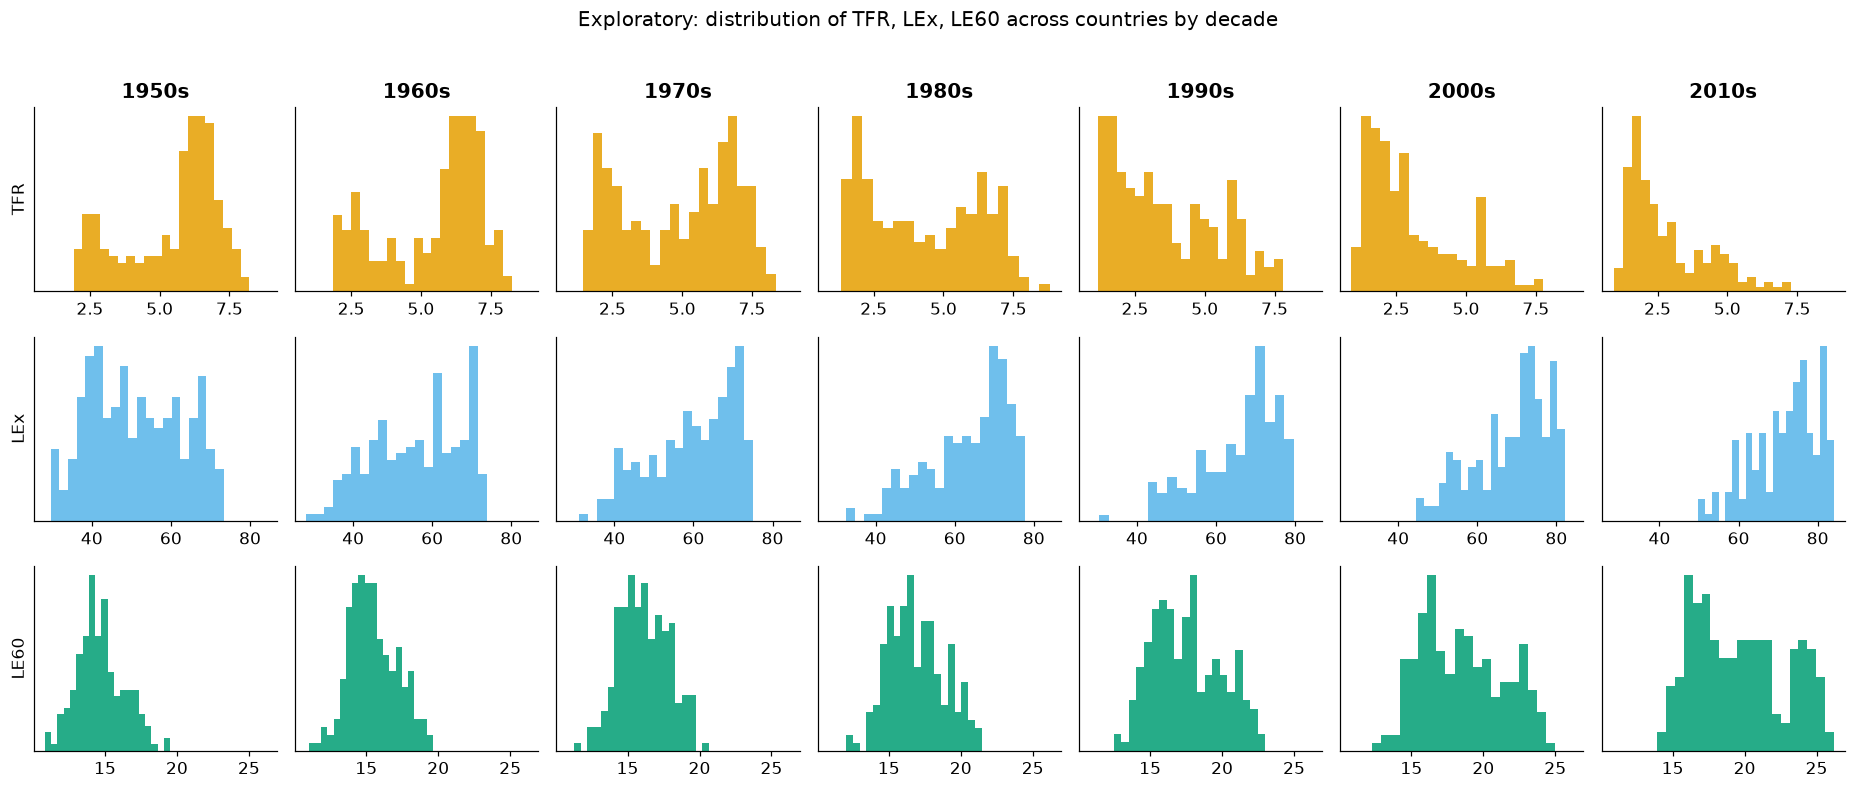

In [86]:
def decade_table(col):
    g = cd[cd['ISO3_code'].isin(primary_codes)].groupby('decade')[col]
    return pd.DataFrame({'min': g.min(), 'p10': g.quantile(.1), 'median': g.median(),
                         'p90': g.quantile(.9), 'max': g.max(), 'sd': g.std()}).round(2)

for col in IND:
    print(f'\n{col} (country decade-medians, primary set)')
    print(decade_table(col))

fig, axes = plt.subplots(3, 7, figsize=(17, 7), sharex='row')
for r, col in enumerate(IND):
    for k, d in enumerate(DECADES):
        v = cd[(cd['decade'] == d) & cd['ISO3_code'].isin(primary_codes)][col]
        axes[r, k].hist(v, bins=20, color=OKABE[r], alpha=.85)
        axes[r, k].set_yticks([])
        if r == 0: axes[r, k].set_title(f'{d}s')
        if k == 0: axes[r, k].set_ylabel(col)
fig.suptitle('Exploratory: distribution of TFR, LEx, LE60 across countries by decade', y=1.02)
plt.tight_layout(); plt.show()

## 4.3 Trajectories

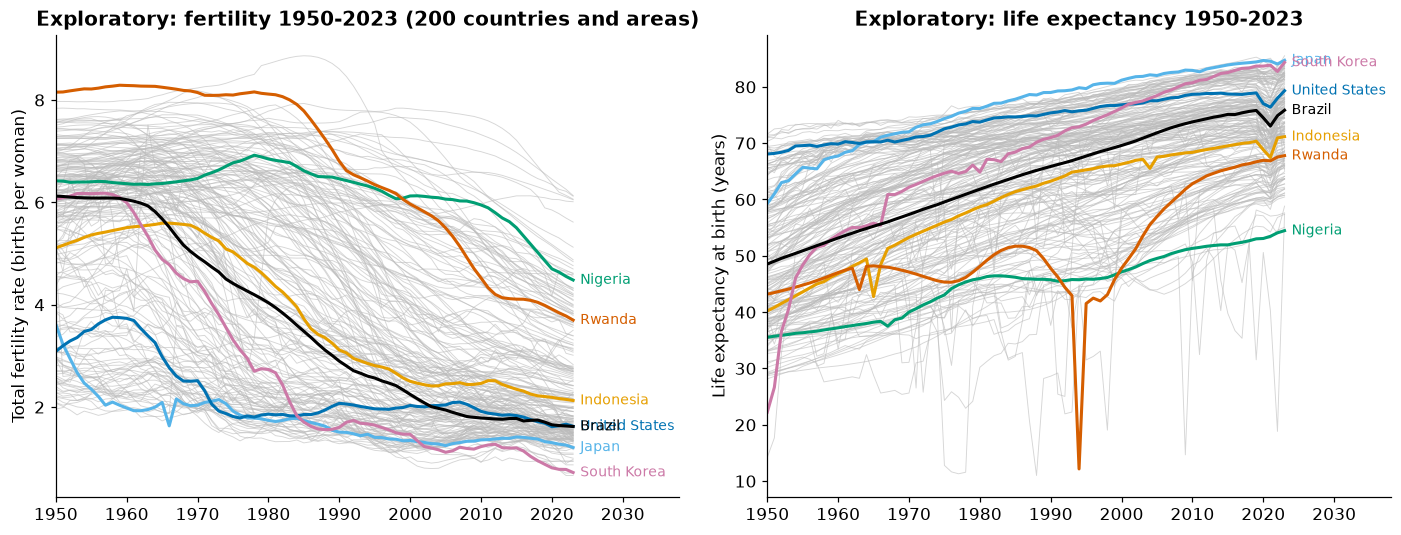

In [87]:
HL = {'IDN': 'Indonesia', 'JPN': 'Japan', 'NGA': 'Nigeria', 'USA': 'United States',
      'RWA': 'Rwanda', 'KOR': 'South Korea', 'BRA': 'Brazil'}
est23 = analysis[(analysis['Time'] <= 2023) & ~analysis['small_pop']].sort_values(['ISO3_code', 'Time'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, lab in zip(axes, ['TFR', 'LEx'],
                        ['Total fertility rate (births per woman)', 'Life expectancy at birth (years)']):
    for iso, g in est23.groupby('ISO3_code'):
        ax.plot(g['Time'], g[col], color='#BBBBBB', lw=.6, alpha=.6)
    for (iso, name), colr in zip(HL.items(), OKABE):
        g = est23[est23['ISO3_code'] == iso]
        if len(g):
            ax.plot(g['Time'], g[col], color=colr, lw=2)
            ax.text(2024, g[col].iloc[-1], name, color=colr, va='center', fontsize=9)
    ax.set_xlim(1950, 2038); ax.set_ylabel(lab)
axes[0].set_title('Exploratory: fertility 1950-2023 (200 countries and areas)')
axes[1].set_title('Exploratory: life expectancy 1950-2023')
plt.tight_layout(); plt.show()

## 4.4 Paths in the TFR–life expectancy plane (prototype of a possible hero figure)

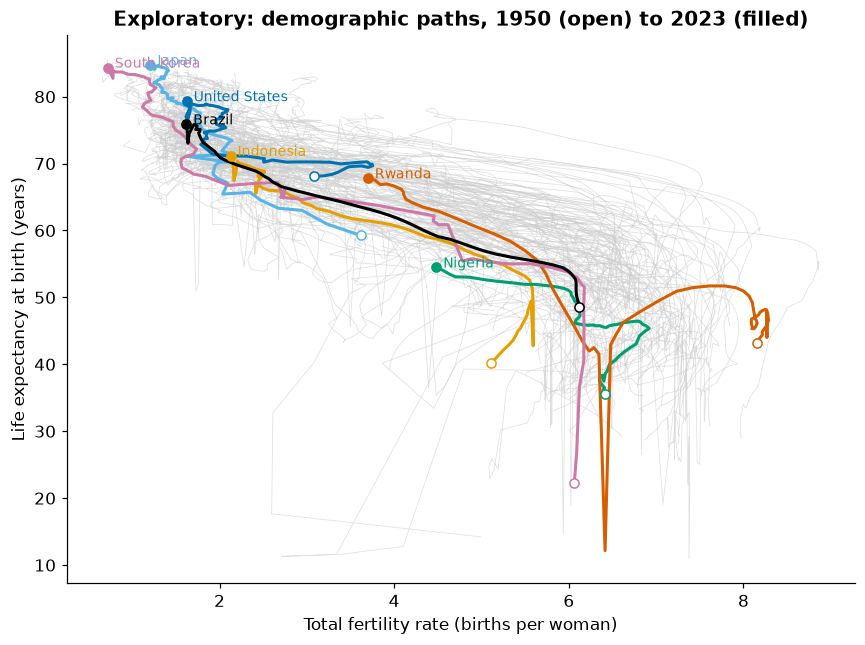

In [88]:
fig, ax = plt.subplots(figsize=(8, 6))
for iso, g in est23.groupby('ISO3_code'):
    ax.plot(g['TFR'], g['LEx'], color='#CCCCCC', lw=.5, alpha=.6)
for (iso, name), colr in zip(HL.items(), OKABE):
    g = est23[est23['ISO3_code'] == iso]
    if len(g):
        ax.plot(g['TFR'], g['LEx'], color=colr, lw=2)
        ax.scatter(g['TFR'].iloc[0], g['LEx'].iloc[0], facecolor='white', edgecolor=colr, zorder=3)   # 1950
        ax.scatter(g['TFR'].iloc[-1], g['LEx'].iloc[-1], color=colr, zorder=3)                         # 2023
        ax.text(g['TFR'].iloc[-1] + .08, g['LEx'].iloc[-1], name, color=colr, fontsize=9)
ax.set_xlabel('Total fertility rate (births per woman)'); ax.set_ylabel('Life expectancy at birth (years)')
ax.set_title('Exploratory: demographic paths, 1950 (open) to 2023 (filled)')
plt.tight_layout(); plt.show()

## 4.5 Redundancy among the 21 features

(236, 21) | NaNs: 0


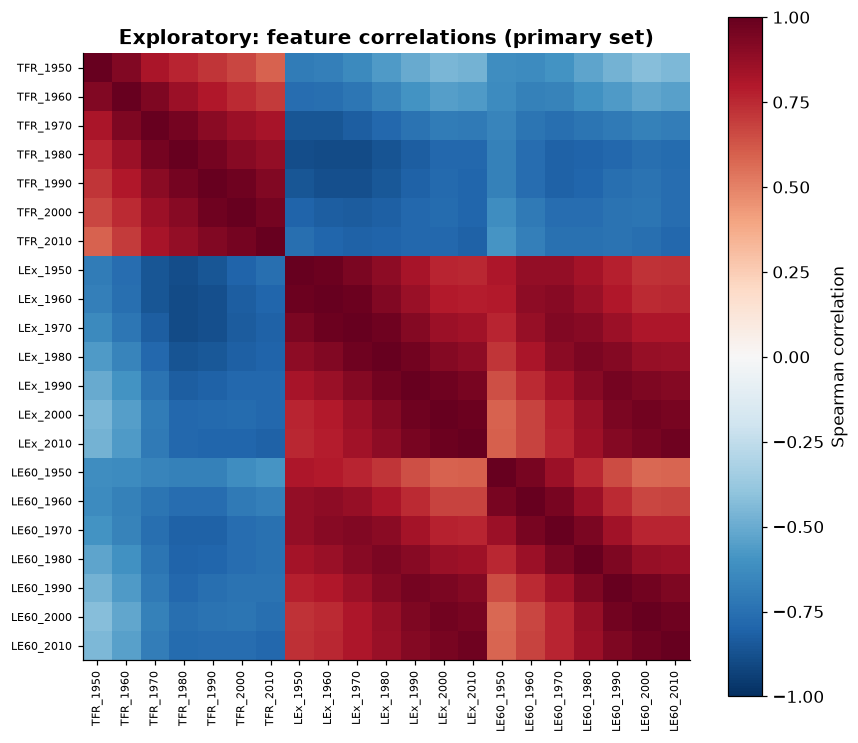

      TFR-LEx  TFR-LE60  LEx-LE60
1950    -0.70     -0.62      0.81
1960    -0.76     -0.68      0.89
1970    -0.83     -0.75      0.93
1980    -0.86     -0.80      0.95
1990    -0.81     -0.76      0.96
2000    -0.77     -0.73      0.96
2010    -0.81     -0.78      0.97


In [89]:
wide = cd.pivot(index='ISO3_code', columns='decade', values=IND)
wide.columns = [f'{i}_{d}' for i, d in wide.columns]
wide = wide[[f'{i}_{d}' for i in IND for d in DECADES]]
print(wide.shape, '| NaNs:', int(wide.isna().sum().sum()))

corr = wide.loc[primary_codes].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(21)); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(21)); ax.set_yticklabels(corr.columns, fontsize=7)
plt.colorbar(im, label='Spearman correlation'); ax.set_title('Exploratory: feature correlations (primary set)')
plt.tight_layout(); plt.show()

same_decade = pd.DataFrame({d: {'TFR-LEx': corr.loc[f'TFR_{d}', f'LEx_{d}'],
                                'TFR-LE60': corr.loc[f'TFR_{d}', f'LE60_{d}'],
                                'LEx-LE60': corr.loc[f'LEx_{d}', f'LE60_{d}']} for d in DECADES}).T.round(2)
print(same_decade)

## 4.6 Skewness and outliers

In [90]:
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad if mad > 0 else s * 0

Xp = wide.loc[primary_codes]
rz = Xp.apply(robust_z)
diag = pd.DataFrame({'skew': Xp.skew().round(2), 'n_|rz|>3.5': (rz.abs() > 3.5).sum()})
print(diag)

worst = rz.abs().max(axis=1).sort_values(ascending=False).head(8)
print('\nCountries with the most extreme robust z-score on any feature:')
print(worst.round(2))

log('Skew and outliers inspected; outliers kept (real events); primary scaling stays z-score as pre-specified; median-IQR scaling is in the sensitivity grid.')

           skew  n_|rz|>3.5
TFR_1950  -0.76           0
TFR_1960  -0.68           0
TFR_1970  -0.21           0
TFR_1980   0.11           0
TFR_1990   0.50           0
TFR_2000   0.88           0
TFR_2010   1.05           6
LEx_1950   0.12           0
LEx_1960  -0.26           0
LEx_1970  -0.55           0
LEx_1980  -0.78           0
LEx_1990  -0.82           1
LEx_2000  -0.68           0
LEx_2010  -0.57           0
LE60_1950  0.32           0
LE60_1960  0.19           0
LE60_1970  0.07           0
LE60_1980  0.19           0
LE60_1990  0.29           0
LE60_2000  0.26           0
LE60_2010  0.27           0

Countries with the most extreme robust z-score on any feature:
ISO3_code
NER    4.67
SOM    4.43
TCD    4.17
SSD    4.14
COD    3.91
MLI    3.86
CAF    3.57
LVA    3.40
dtype: float64
LOG: Skew and outliers inspected; outliers kept (real events); primary scaling stays z-score as pre-specified; median-IQR scaling is in the sensitivity grid.


In [100]:
top = rz.abs().max(axis=1).sort_values(ascending=False).head(8).index
for iso in top:
    f = rz.loc[iso].abs().idxmax()
    print(iso, meta.loc[iso, 'Location'], '|', f, '| robust z =', round(rz.loc[iso, f], 2),
          '| value =', round(Xp.loc[iso, f], 2))

NER Niger | TFR_2010 | robust z = 4.67 | value = 7.28
SOM Somalia | TFR_2010 | robust z = 4.43 | value = 7.02
TCD Chad | TFR_2010 | robust z = 4.17 | value = 6.74
SSD South Sudan | LEx_1990 | robust z = -4.14 | value = 30.35
COD Democratic Republic of the Congo | TFR_2010 | robust z = 3.91 | value = 6.46
MLI Mali | TFR_2010 | robust z = 3.86 | value = 6.41
CAF Central African Republic | TFR_2010 | robust z = 3.57 | value = 6.09
LVA Latvia | TFR_1950 | robust z = -3.4 | value = 1.92


## 4.7 Build and save the fatures matrices

In [93]:
X_primary = wide.loc[primary_codes].copy()
X_all = wide.loc[all_codes].copy()
print('X_primary', X_primary.shape, '| X_all', X_all.shape,
      '| NaNs:', int(X_primary.isna().sum().sum() + X_all.isna().sum().sum()))

out_dir = DATA_DIR / 'processed'
X_primary.to_csv(out_dir / 'X_primary_decade_medians.csv')
X_all.to_csv(out_dir / 'X_all_decade_medians.csv')
log('Feature matrices built: decade medians of TFR, LEx, LE60 for 1950s-2010s (21 features); primary n=200, all n=236.')

X_primary (200, 21) | X_all (236, 21) | NaNs: 0
LOG: Feature matrices built: decade medians of TFR, LEx, LE60 for 1950s-2010s (21 features); primary n=200, all n=236.


## 4.8 Held-out validation table

In [94]:
h = analysis[(analysis['Time'] >= 2010) & (analysis['Time'] <= 2019)]
held = h.groupby('ISO3_code').agg(MedianAgePop=('MedianAgePop', 'median'),
                                  CNMR=('CNMR', 'median'),
                                  PopGrowthRate=('PopGrowthRate', 'median'),
                                  PopDensity=('PopDensity', 'median'),
                                  Pop_thousands=('TPopulation1July', 'median'))
held['log10_pop'] = np.log10(held['Pop_thousands'] * 1000)
held['LE60_sex_gap'] = (h['LE60Female'] - h['LE60Male']).groupby(h['ISO3_code']).median()

meta = (analysis.drop_duplicates('ISO3_code')
        .set_index('ISO3_code')[['Location', 'Region', 'Subregion', 'small_pop']])
held = held.join(meta)
held.to_csv(out_dir / 'heldout_2010s_medians.csv')
print(held.shape); print(held.describe().T[['min', '50%', 'max']].round(2))
log('Held-out variables summarised as 2010-2019 medians (specified before any clustering).')

(236, 11)
                 min      50%         max
MedianAgePop   14.32    29.12       52.35
CNMR          -39.26    -0.25       44.35
PopGrowthRate  -2.02     1.12        5.40
PopDensity      0.14    92.70    24458.05
Pop_thousands   1.71  5100.16  1392043.07
log10_pop       3.23     6.71        9.14
LE60_sex_gap    0.36     3.13        7.52
LOG: Held-out variables summarised as 2010-2019 medians (specified before any clustering).


## 4.9 Record the plan clarifications

In [95]:
addendum = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Written after exploratory analysis of distributions, before any clustering or hypothesis test.',
    'clarifications': [
        'Held-out variables are summarised as 2010-2019 medians per country.',
        'Clusters treat every country/area equally (unweighted); population-weighted summaries are reported separately.',
        'Primary scaling remains z-score; median-IQR scaling is a sensitivity run.'],
    'exploration_log': explog,
}
(DATA_DIR.parent / 'analysis_plan_addendum.json').write_text(json.dumps(addendum, indent=2), encoding='utf-8')
print('Addendum saved')

Addendum saved


In [96]:
g = cd[cd['ISO3_code'].isin(primary_codes)].groupby('decade')[IND]
print(pd.concat({'SD': g.std(), 'mean': g.mean(), 'CV': g.std() / g.mean()}, axis=1).round(3))

           SD                  mean                     CV              
          TFR     LEx   LE60    TFR     LEx    LE60    TFR    LEx   LE60
decade                                                                  
1950    1.665  11.498  1.635  5.482  51.193  14.701  0.304  0.225  0.111
1960    1.780  11.284  1.666  5.435  56.036  15.463  0.327  0.201  0.108
1970    1.994  10.660  1.717  4.852  59.830  16.145  0.411  0.178  0.106
1980    2.012  10.147  1.954  4.296  63.357  16.916  0.468  0.160  0.115
1990    1.828   9.958  2.380  3.622  65.680  17.545  0.505  0.152  0.136
2000    1.651   9.329  2.895  3.079  68.642  18.537  0.536  0.136  0.156
2010    1.407   8.102  3.185  2.802  71.783  19.689  0.502  0.113  0.162


## 4.10 Record the addendum

In [97]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8')) if p.exists() else {}
add['entry_1'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Written after exploratory analysis of distributions, before any clustering or hypothesis test.',
    'clarifications': [
        'Held-out variables are 2010-2019 medians per country.',
        'Clusters treat every country/area equally; population-weighted summaries reported separately.',
        'Primary scaling remains z-score; median-IQR scaling is a sensitivity run.',
        'Dispersion over time is reported as SD and CV.'],
}
add['entry_2'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'After viewing exploratory plots, still before any clustering or hypothesis test.',
    'observations': [
        'Countries mostly travel one common TFR-LEx corridor at different times (stage/timing differences).',
        'LEx dispersion falls 1950s->2010s while LE60 dispersion rises (exploratory).',
        'Only 7 of 4200 feature values have |robust z| > 3.5.'],
    'additions': [
        'E3: residual pathways beyond stage (LE60 net of LEx; mortality-fertility transition lag, censoring flagged).',
        'E4: LEx convergence vs LE60 divergence, with caveat on model-based older-age estimates.',
        'If no k passes the pre-specified criteria, report the groups as partitions of a continuum.'],
    'hypotheses_changed': False,
}
add['exploration_log'] = explog
p.write_text(json.dumps(add, indent=2), encoding='utf-8')
print('Addendum saved')

Addendum saved


# 5 PCA, clustering, stability, and the decision rule

## 5.0 Record the clasifications

In [98]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8'))
add['entry_3'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Written BEFORE any clustering was run.',
    'decision_rule_clarifications': [
        'The k-selection rule is applied to every (algorithm, k) pair. Eligible = smallest cluster share >= 5% and silhouette >= 0.25.',
        'Choose the eligible pair with the highest median bootstrap ARI; differences < 0.02 are ties, resolved by smaller k, then order kmeans, ward, gmm.',
        'If no pair is eligible, report that no clear discrete structure was found.',
        'Pre-declared secondary result: same rule restricted to k in 3..8 ("finer partition"), because stability rules favour k=2 for continuous data. Both results are reported.',
        'PCA keeps the smallest number of components explaining >= 90% variance on the full primary set; bootstrap refits scaler and PCA on each 80% subsample.',
        'Small-population countries are assigned out of sample to the nearest cluster centroid.',
        'Cluster labels are letters ordered by PC1 for readability only; they carry no value judgement.'],
}
p.write_text(json.dumps(add, indent=2), encoding='utf-8')
print('Addendum entry_3 saved')

Addendum entry_3 saved


## 5.1 Scalling and PCA

Variance explained (first 6): [0.786 0.083 0.049 0.031 0.015 0.01 ]
Cumulative: [0.786 0.869 0.918 0.95  0.965 0.975]
Components kept (>= 90%): 3
            PC1   PC2   PC3
TFR_1950  -0.18  0.42  0.12
TFR_1960  -0.19  0.38  0.17
TFR_1970  -0.22  0.22  0.24
TFR_1980  -0.23  0.10  0.25
TFR_1990  -0.23  0.01  0.31
TFR_2000  -0.22 -0.09  0.36
TFR_2010  -0.21 -0.14  0.36
LEx_1950   0.23 -0.17  0.05
LEx_1960   0.23 -0.10  0.03
LEx_1970   0.23  0.01  0.04
LEx_1980   0.23  0.12  0.04
LEx_1990   0.23  0.23 -0.01
LEx_2000   0.22  0.30 -0.04
LEx_2010   0.22  0.28 -0.04
LE60_1950  0.19 -0.28  0.37
LE60_1960  0.21 -0.23  0.29
LE60_1970  0.22 -0.11  0.30
LE60_1980  0.23  0.04  0.29
LE60_1990  0.22  0.19  0.22
LE60_2000  0.21  0.26  0.16
LE60_2010  0.22  0.25  0.11


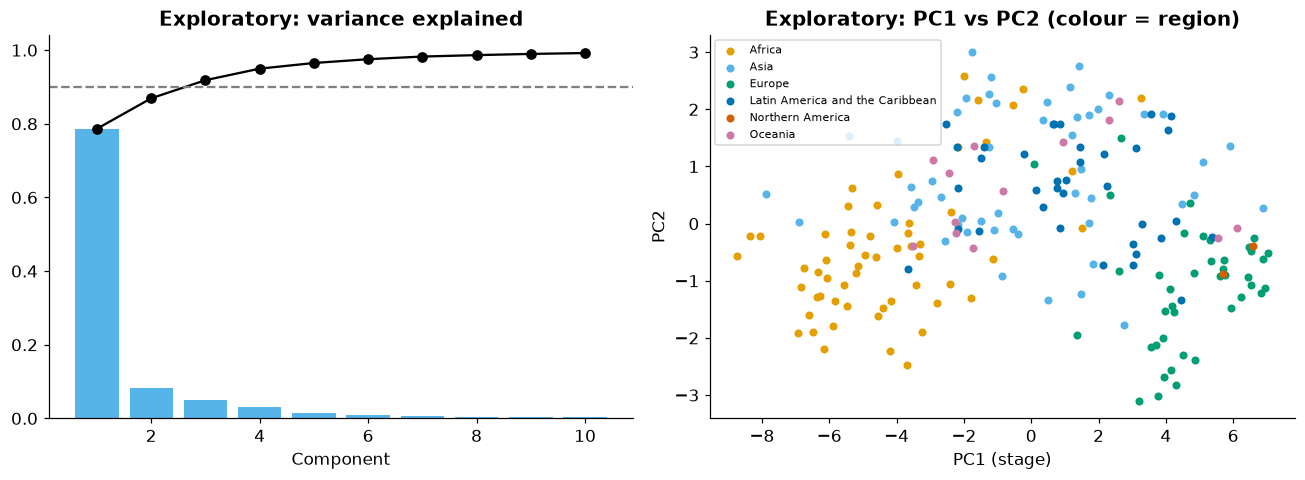

In [ ]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)

SEED, K_RANGE, N_BOOT, SUB = 42, list(range(2, 11)), 500, 0.8
ALGOS = ['kmeans', 'ward', 'gmm']

scaler = StandardScaler().fit(X_primary.values)
Z = scaler.transform(X_primary.values)
evr = PCA().fit(Z).explained_variance_ratio_
cum = np.cumsum(evr)
N_COMP = int(np.searchsorted(cum, 0.90) + 1)
print('Variance explained (first 6):', np.round(evr[:6], 3))
print('Cumulative:', np.round(cum[:6], 3))
print('Components kept (>= 90%):', N_COMP)

pca = PCA(n_components=N_COMP).fit(Z)
if pca.components_[0, list(X_primary.columns).index('LEx_2010')] < 0:
    pca.components_[0] *= -1                      # flip the fitted object itself
S = pca.transform(Z)
load = pd.DataFrame(pca.components_.T, index=X_primary.columns,
                    columns=[f'PC{i+1}' for i in range(N_COMP)])
if load.loc['LEx_2010', 'PC1'] < 0:            # orient PC1: higher = longer life expectancy
    load['PC1'] *= -1; S[:, 0] *= -1
print(load.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(range(1, 11), evr[:10], color='#56B4E9'); ax[0].plot(range(1, 11), cum[:10], 'ko-')
ax[0].axhline(.9, ls='--', c='gray'); ax[0].set_xlabel('Component'); ax[0].set_title('Exploratory: variance explained')
regs = meta.loc[X_primary.index, 'Region']
for r, colr in zip(sorted(regs.unique()), OKABE):
    m = (regs == r).values
    ax[1].scatter(S[m, 0], S[m, 1], s=18, color=colr, label=r)
ax[1].set_xlabel('PC1 (stage)'); ax[1].set_ylabel('PC2'); ax[1].legend(fontsize=7)
ax[1].set_title('Exploratory: PC1 vs PC2 (colour = region)')
plt.tight_layout(); plt.show()

## 5.2 Clustering functions and criteria on the full sample

In [103]:
def fit_labels(Sx, algo, k, seed=SEED, n_init=10):
    if algo == 'kmeans':
        return KMeans(k, n_init=n_init, random_state=seed).fit_predict(Sx)
    if algo == 'ward':
        return AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Sx)
    return GaussianMixture(k, covariance_type='full', n_init=3, reg_covar=1e-4,
                           random_state=seed).fit(Sx).predict(Sx)

rows, base_labels = [], {}
for algo in ALGOS:
    for k in K_RANGE:
        lab = fit_labels(S, algo, k)
        base_labels[(algo, k)] = lab
        sizes = np.bincount(lab, minlength=k)
        ok = len(np.unique(lab)) >= 2
        row = dict(algo=algo, k=k, min_share=sizes.min() / len(lab),
                   silhouette=silhouette_score(S, lab) if ok else np.nan,
                   CH=calinski_harabasz_score(S, lab) if ok else np.nan,
                   DB=davies_bouldin_score(S, lab) if ok else np.nan)
        if algo == 'gmm':
            row['BIC'] = GaussianMixture(k, covariance_type='full', n_init=3, reg_covar=1e-4,
                                         random_state=SEED).fit(S).bic(S)
        rows.append(row)
crit = pd.DataFrame(rows)

def gap_statistic(Sx, ks, B=50, seed=SEED):
    r = np.random.default_rng(seed); lo, hi = Sx.min(0), Sx.max(0); out = []
    for k in ks:
        w = np.log(KMeans(k, n_init=10, random_state=seed).fit(Sx).inertia_)
        wr = np.array([np.log(KMeans(k, n_init=3, random_state=seed)
                              .fit(r.uniform(lo, hi, Sx.shape)).inertia_) for _ in range(B)])
        out.append((k, wr.mean() - w, wr.std() * np.sqrt(1 + 1 / B)))
    return pd.DataFrame(out, columns=['k', 'gap', 's'])

gap = gap_statistic(S, K_RANGE)
tib = next((int(gap.loc[i, 'k']) for i in range(len(gap) - 1)
            if gap.loc[i, 'gap'] >= gap.loc[i + 1, 'gap'] - gap.loc[i + 1, 's']), None)
print('Gap statistic (Tibshirani rule) suggests k =', tib)
print(crit.round(3).to_string(index=False))

Gap statistic (Tibshirani rule) suggests k = 5
  algo  k  min_share  silhouette      CH    DB      BIC
kmeans  2      0.490       0.517 353.070 0.701      NaN
kmeans  3      0.275       0.431 335.651 0.768      NaN
kmeans  4      0.195       0.394 324.385 0.858      NaN
kmeans  5      0.140       0.381 298.805 0.867      NaN
kmeans  6      0.125       0.343 279.014 0.959      NaN
kmeans  7      0.100       0.340 265.043 0.985      NaN
kmeans  8      0.090       0.322 253.289 1.053      NaN
kmeans  9      0.060       0.320 243.665 1.028      NaN
kmeans 10      0.025       0.332 237.881 0.988      NaN
  ward  2      0.280       0.437 203.416 0.698      NaN
  ward  3      0.230       0.408 290.421 0.745      NaN
  ward  4      0.230       0.389 319.199 0.892      NaN
  ward  5      0.085       0.356 277.054 0.911      NaN
  ward  6      0.085       0.310 252.675 0.989      NaN
  ward  7      0.085       0.301 240.617 1.030      NaN
  ward  8      0.085       0.292 230.352 1.040      NaN
 

## 5.3 Bootstrap stability

In [ ]:
def match_to_base(b, lab, k):
    cont = np.zeros((k, k), int); np.add.at(cont, (b, lab), 1)
    r, c = linear_sum_assignment(-cont)
    mp = dict(zip(c, r))
    return np.array([mp.get(l, -1) for l in lab])

Xv = X_primary.values; n = len(Xv); m = int(SUB * n)
rng = np.random.default_rng(SEED)
subsamples = [np.sort(rng.choice(n, m, replace=False)) for _ in range(N_BOOT)]
emb = [PCA(n_components=N_COMP).fit_transform(StandardScaler().fit_transform(Xv[i])) for i in subsamples]

stab_rows, keep = [], {}
t0 = time.time()
for algo in ALGOS:
    for k in K_RANGE:
        base = base_labels[(algo, k)]
        aris, kept, seen = [], np.zeros(n), np.zeros(n)
        for idx, Sb in zip(subsamples, emb):
            lab = fit_labels(Sb, algo, k)
            b = base[idx]
            aris.append(adjusted_rand_score(b, lab))
            kept[idx] += (match_to_base(b, lab, k) == b); seen[idx] += 1
        kp = kept / np.maximum(seen, 1); keep[(algo, k)] = kp
        stab_rows.append(dict(algo=algo, k=k, median_ARI=np.median(aris),
                              ARI_q05=np.quantile(aris, .05), ARI_q95=np.quantile(aris, .95),
                              pct_keep80=(kp >= .8).mean(), mean_keep=kp.mean()))
        print(f'{algo:6s} k={k:2d} median ARI={np.median(aris):.3f}  ({time.time()-t0:.0f}s)')
stab = pd.DataFrame(stab_rows)

kmeans k= 2 median ARI=1.000  (12s)
kmeans k= 3 median ARI=0.979  (25s)
kmeans k= 4 median ARI=0.922  (39s)
kmeans k= 5 median ARI=0.953  (53s)
kmeans k= 6 median ARI=0.787  (67s)
kmeans k= 7 median ARI=0.843  (81s)
kmeans k= 8 median ARI=0.749  (96s)
kmeans k= 9 median ARI=0.737  (111s)
kmeans k=10 median ARI=0.739  (128s)
ward   k= 2 median ARI=0.299  (130s)
ward   k= 3 median ARI=0.479  (131s)
ward   k= 4 median ARI=0.816  (133s)
ward   k= 5 median ARI=0.744  (134s)
ward   k= 6 median ARI=0.699  (136s)
ward   k= 7 median ARI=0.681  (137s)
ward   k= 8 median ARI=0.643  (139s)
ward   k= 9 median ARI=0.643  (141s)
ward   k=10 median ARI=0.648  (142s)
gmm    k= 2 median ARI=0.924  (170s)
gmm    k= 3 median ARI=0.870  (193s)
gmm    k= 4 median ARI=0.514  (222s)
gmm    k= 5 median ARI=0.793  (257s)
gmm    k= 6 median ARI=0.634  (300s)
gmm    k= 7 median ARI=0.618  (346s)
gmm    k= 8 median ARI=0.617  (405s)
gmm    k= 9 median ARI=0.546  (468s)
gmm    k=10 median ARI=0.562  (538s)


## 5.4 Apply the pre-specified rule

In [104]:
crit = crit.drop(columns=[c for c in stab.columns if c not in ('algo', 'k') and c in crit.columns]).merge(stab, on=['algo', 'k'])
crit['eligible'] = (crit['min_share'] >= 0.05) & (crit['silhouette'] >= 0.25)

def choose(df, kmin, kmax):
    e = df[df['eligible'] & df['k'].between(kmin, kmax)]
    if e.empty: return None
    tied = e[e['median_ARI'] >= e['median_ARI'].max() - 0.02].copy()
    tied['o'] = tied['algo'].map({'kmeans': 0, 'ward': 1, 'gmm': 2})
    return tied.sort_values(['k', 'o']).iloc[0]

primary_choice, finer_choice = choose(crit, 2, 10), choose(crit, 3, 8)
for name, ch in [('PRIMARY (k 2-10)', primary_choice), ('FINER (k 3-8, pre-declared)', finer_choice)]:
    print(f'\n{name}:')
    if ch is None:
        print('No eligible (algorithm, k): report no clear discrete structure.')
    else:
        print({a: (round(float(v), 3) if not isinstance(v, str) else v)
               for a, v in ch[['algo', 'k', 'silhouette', 'median_ARI', 'pct_keep80', 'min_share']].items()})

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for algo, colr in zip(ALGOS, OKABE):
    d = crit[crit['algo'] == algo]
    axs[0, 0].plot(d['k'], d['silhouette'], 'o-', color=colr, label=algo)
    axs[0, 1].plot(d['k'], d['CH'], 'o-', color=colr)
    axs[0, 2].plot(d['k'], d['DB'], 'o-', color=colr)
    axs[1, 0].plot(d['k'], d['median_ARI'], 'o-', color=colr)
axs[0, 0].axhline(.25, ls='--', c='gray'); axs[1, 0].axhline(.7, ls='--', c='gray')
g = crit[crit['algo'] == 'gmm']; axs[1, 1].plot(g['k'], g['BIC'], 'o-', color=OKABE[2])
axs[1, 2].errorbar(gap['k'], gap['gap'], yerr=gap['s'], fmt='o-', color=OKABE[0])
for a, t in zip(axs.ravel(), ['Silhouette (>= 0.25)', 'Calinski-Harabasz', 'Davies-Bouldin (lower = better)',
                              'Median bootstrap ARI (>= 0.7)', 'GMM BIC (lower = better)', 'Gap statistic (k-means)']):
    a.set_title(t); a.set_xlabel('k')
axs[0, 0].legend(); plt.tight_layout(); plt.show()

out_dir = DATA_DIR / 'processed'
crit.to_csv(out_dir / 'step5_criteria.csv', index=False)
with open(out_dir / 'step5_results.pkl', 'wb') as f:
    pickle.dump(dict(crit=crit, base_labels=base_labels, keep=keep, S=S, N_COMP=N_COMP, load=load,
                     primary=primary_choice, finer=finer_choice, gap=gap), f)
print('Saved step5_results.pkl')

NameError: name 'stab' is not defined